# Дело Магазина-Х: расследование в данных

Это рабочий ноутбук одного расследования: от сырых CSV до проведённого A/B-теста и решения, которое приняло правление.

**Задача.** Продакт принёс тикет: «повторные покупки просели, разберись». За жалобой не было ни цифр, ни сегмента, ни даты — только ощущение. Нужно было превратить её в измеримый вопрос, найти причину и доказать её.

**Что внутри.** Шесть фаз, каждая отвечает на свой вопрос:

1. **Данные** — что вообще лежит в четырёх таблицах и в каком они состоянии.
2. **Метрики** — магазин здоров или болен: DAU/WAU/MAU, конверсия, чек, ARPU, LTV.
3. **Когорты** — старые пользователи уходят или новые хуже: retention-матрица, LTV по каналам.
4. **Воронки** — где именно теряются покупатели: общая, сегментированная, во времени.
5. **A/B-тесты** — правда ли виноват редизайн: шум, p-value, дизайн, анализ, подглядывание.
6. **Отчёт** — как превратить правду в решение: страница для правления и график.

**Стек:** Python 3.10+, pandas, numpy, matplotlib.

**Данные:** публичные CSV курса «Продуктовая аналитика на Python» (Python Academy). Для офлайн-работы скачайте файлы из `https://python-academy.org/static/product-analytics/dataset/` и замените `base` на путь к локальной папке.

**Как читать.** Каждая фаза самодостаточна: свои импорты, свой `base`, свой набор ячеек. Можно открыть любую — она запустится отдельно. Это сделано намеренно: читатель заходит в интересующую точку, а не идёт сверху вниз.

**Итог расследования.** Релиз редизайна мобильного чекаута 1 апреля уронил конверсию шага корзина → оформление с 68% до 49%. Магазин недополучал около 14 млн ₽ в месяц. A/B-тест доказал причинность: возврат старой формы поднял конверсию до 69.5% (p < 0.001). Правление приняло решение за четыре минуты.

# Фаза 1. Первый взгляд на данные

Первая фаза расследования — понять, что вообще лежит в данных. Не строить графики, не считать метрики, а ответить на четыре вопроса: какой период покрывают таблицы, есть ли пропуски, есть ли дубли по ключам, разумны ли диапазоны значений.

Без этой станции любая метрика — красивая ложь на грязных данных.

**Что найдём:** четыре таблицы, год истории магазина, пропуски в гео, дубли в сессиях и длинный хвост в суммах заказов.

## Датасет Магазина-Х: первый взгляд

### Загружаем все таблицы

In [1]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

users = pd.read_csv(f"{base}/users.csv", parse_dates=["signup_date"])
products = pd.read_csv(f"{base}/products.csv")
sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])
orders = pd.read_csv(f"{base}/orders.csv", parse_dates=["created_at"])

print(f"users:    {len(users):>7,}")
print(f"products: {len(products):>7,}")
print(f"sessions: {len(sessions):>7,}")
print(f"orders:   {len(orders):>7,}")

users:      6,000
products:     300
sessions:  68,668
orders:     7,327


### Смотрим users

In [2]:
print(users.head())

   user_id signup_date       source country device_first age_bucket  \
0  u_00001  2026-04-04  paid_social      KZ       mobile      35-44   
1  u_00002  2025-12-14      organic      RU      desktop      25-34   
2  u_00003  2026-04-26  paid_social      RU       mobile      18-24   
3  u_00004  2026-03-15      organic      AM       mobile      18-24   
4  u_00005  2025-07-30      organic      RU       tablet      25-34   

   marketing_opt_in  
0             False  
1              True  
2              True  
3              True  
4              True  


In [3]:
print(users.dtypes)

user_id                     object
signup_date         datetime64[ns]
source                      object
country                     object
device_first                object
age_bucket                  object
marketing_opt_in              bool
dtype: object


### Смотрим sessions

In [4]:
print(sessions[["session_id", "user_id", "started_at", "device", "reached_step"]].head())

  session_id  user_id          started_at   device reached_step
0   s_000001  u_00001 2026-04-09 21:14:41   mobile         home
1   s_000002  u_00001 2026-04-27 18:13:15  desktop      product
2   s_000003  u_00001 2026-04-27 15:14:39   mobile      product
3   s_000004  u_00002 2026-04-20 05:04:22  desktop      product
4   s_000005  u_00002 2026-01-08 14:42:20   mobile      product


### Смотрим orders

In [5]:
print(orders[["order_id", "user_id", "session_id", "total_rub", "status"]].head())

  order_id  user_id session_id  total_rub     status
0  o_00001  u_00002   s_000007      25150  completed
1  o_00002  u_00003   s_000013      31650  completed
2  o_00003  u_00009   s_000046      13900  completed
3  o_00004  u_00010   s_000052        690  completed
4  o_00005  u_00013   s_000077       2100  completed


### Первая проверка: что важно посмотреть сразу

In [6]:
print(f"users:    {users['signup_date'].min().date()} → {users['signup_date'].max().date()}")
print(f"sessions: {sessions['started_at'].min().date()} → {sessions['started_at'].max().date()}")
print(f"orders:   {orders['created_at'].min().date()} → {orders['created_at'].max().date()}")

users:    2025-06-01 → 2026-05-31
sessions: 2025-06-01 → 2026-05-31
orders:   2025-06-01 → 2026-06-01


In [7]:
print(users.isna().sum())
print(sessions.isna().sum())

user_id               0
signup_date           0
source                0
country               0
device_first          0
age_bucket          309
marketing_opt_in      0
dtype: int64
session_id         0
user_id            0
started_at         0
duration_sec       0
device             0
source             0
country         2078
pages_viewed       0
reached_step       0
dtype: int64


In [8]:
print(f"дублей user_id:    {users['user_id'].duplicated().sum()}")
print(f"дублей session_id: {sessions['session_id'].duplicated().sum()}")
print(f"дублей order_id:   {orders['order_id'].duplicated().sum()}")

дублей user_id:    0
дублей session_id: 8
дублей order_id:   0


In [9]:
print(orders["total_rub"].describe())

count      7327.000000
mean      34012.965743
std       34653.869367
min         230.000000
25%        8650.000000
50%       21900.000000
75%       47100.000000
max      243400.000000
Name: total_rub, dtype: float64


## Срезы и фильтры: быстрые вопросы к данным

In [10]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

users = pd.read_csv(f"{base}/users.csv", parse_dates=["signup_date"])
orders = pd.read_csv(f"{base}/orders.csv", parse_dates=["created_at"])
sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])

### Булева маска: основа всех фильтров

In [11]:
mask = orders["items_count"] == 1
print(mask.head())

0    False
1    False
2     True
3     True
4     True
Name: items_count, dtype: bool


In [12]:
completed = orders[orders["status"] == "completed"]
print(f"завершённых заказов: {len(completed)} из {len(orders)}")

завершённых заказов: 6986 из 7327


### Приём аналитика: среднее от маски

In [13]:
print(f"доля завершённых: {(orders['status'] == 'completed').mean():.1%}")
print(f"доля мобильных сессий: {(sessions['device'] == 'mobile').mean():.1%}")

доля завершённых: 95.3%
доля мобильных сессий: 57.9%


### Несколько условий: скобки обязательны

In [14]:
march = orders[
    (orders["created_at"] >= "2026-03-01") & (orders["created_at"] < "2026-04-01")
]
print(f"заказов в марте: {len(march)}")

заказов в марте: 1025


In [15]:
not_organic = users[~(users["source"] == "organic")]
print(f"пользователей из платных и партнёрских каналов: {len(not_organic)}")

пользователей из платных и партнёрских каналов: 4498


### Сначала узнай значения, потом фильтруй

In [16]:
print(users["source"].unique())

['paid_social' 'organic' 'paid_search' 'referral' 'email']


### isin: значение из списка

In [17]:
cis = users[users["country"].isin(["KZ", "BY", "UA"])]
print(f"пользователей из KZ, BY, UA: {len(cis)}")

пользователей из KZ, BY, UA: 1835


### query: те же фильтры, читаемее

In [18]:
big = orders.query("total_rub > 50_000 and status == 'completed'")
print(f"крупных завершённых заказов: {len(big)}")

крупных завершённых заказов: 1639


### loc: строки и колонки одним вызовом

In [19]:
kz = users.loc[users["country"] == "KZ", ["user_id", "signup_date", "source"]]
print(f"пользователей из KZ: {len(kz)}")
print(kz.head())

пользователей из KZ: 921
    user_id signup_date       source
0   u_00001  2026-04-04  paid_social
18  u_00019  2026-04-18  paid_search
25  u_00026  2025-09-17     referral
29  u_00030  2026-03-11      organic
31  u_00032  2026-05-23  paid_social


## Группировки: вся картина одной строкой

In [20]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

users = pd.read_csv(f"{base}/users.csv", parse_dates=["signup_date"])
orders = pd.read_csv(f"{base}/orders.csv", parse_dates=["created_at"])

### value_counts: сколько строк в каждой группе

In [21]:
print(users["source"].value_counts())

source
paid_social    2082
organic        1502
paid_search    1243
email           594
referral        579
Name: count, dtype: int64


In [22]:
print((users["source"].value_counts(normalize=True) * 100).round(1))

source
paid_social    34.7
organic        25.0
paid_search    20.7
email           9.9
referral        9.6
Name: proportion, dtype: float64


### Как устроен groupby: разделить, применить, собрать

In [23]:
print(orders.groupby("items_count")["total_rub"].mean().round(0))

items_count
1    16739.0
2    33888.0
3    51248.0
Name: total_rub, dtype: float64


### Несколько метрик сразу: agg

In [24]:
print(orders.groupby("status").agg(
    orders=("order_id", "count"),     # имя_колонки=(откуда, чем считать)
    revenue=("total_rub", "sum"),
    avg_order=("total_rub", "mean"),
).round(0))

           orders    revenue  avg_order
status                                 
cancelled     205    7136750    34813.0
completed    6986  236572460    33864.0
returned      136    5503790    40469.0


### Заказы по месяцам: первый взгляд на динамику

In [25]:
print(orders.groupby(orders["created_at"].dt.to_period("M")).size())

created_at
2025-06      13
2025-07      45
2025-08      90
2025-09     136
2025-10     230
2025-11     384
2025-12     468
2026-01     576
2026-02     664
2026-03    1025
2026-04    1267
2026-05    2427
2026-06       2
Freq: M, dtype: int64


## Объединение таблиц: выручка по странам

In [26]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

users = pd.read_csv(f"{base}/users.csv", parse_dates=["signup_date"])
orders = pd.read_csv(f"{base}/orders.csv", parse_dates=["created_at"])
sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])

### merge: приклеить колонки по ключу

In [27]:
merged = orders.merge(users[["user_id", "country"]], on="user_id")

print(f"до:    {orders.shape}")
print(f"после: {merged.shape}")
print(merged[["order_id", "user_id", "total_rub", "status", "country"]].head())

до:    (7327, 7)
после: (7327, 8)
  order_id  user_id  total_rub     status country
0  o_00001  u_00002      25150  completed      RU
1  o_00002  u_00003      31650  completed      RU
2  o_00003  u_00009      13900  completed      UA
3  o_00004  u_00010        690  completed      RU
4  o_00005  u_00013       2100  completed      US


### Выручка по странам: инструменты складываются

In [28]:
completed = merged[merged["status"] == "completed"]
revenue = completed.groupby("country")["total_rub"].sum().sort_values(ascending=False)
print(revenue)

country
RU    118048670
KZ     36474780
BY     22779310
UA     12280270
US     12220350
DE     10534790
PL      7401090
TR      7242150
AM      5434320
GE      4156730
Name: total_rub, dtype: int64


In [29]:
print((revenue / 1e6).round(1))

country
RU    118.0
KZ     36.5
BY     22.8
UA     12.3
US     12.2
DE     10.5
PL      7.4
TR      7.2
AM      5.4
GE      4.2
Name: total_rub, dtype: float64


### Ловушка: после merge строк стало больше

In [30]:
u2o = users.merge(orders[["user_id", "total_rub"]], on="user_id")

print(f"до:    {users.shape}")
print(f"после: {u2o.shape}")

до:    (6000, 7)
после: (7327, 8)


### inner и left: кого мы потеряли

In [31]:
left = users.merge(orders[["user_id", "order_id"]], on="user_id", how="left")

print(f"строк: {left.shape[0]}")
print(f"пользователей без заказов: {left['order_id'].isna().sum()}")

строк: 9630
пользователей без заказов: 2303


In [32]:
buyers = orders["user_id"].nunique()
print(f"покупателей: {buyers} из {len(users)} ({buyers / len(users):.1%})")

покупателей: 3697 из 6000 (61.6%)


### Когда имена колонок совпадают

In [33]:
m = sessions.merge(users, on="user_id")
print([c for c in m.columns if c.endswith("_x") or c.endswith("_y")])

['source_x', 'country_x', 'source_y', 'country_y']


## Работа с датами: что происходило в апреле

In [34]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

orders = pd.read_csv(f"{base}/orders.csv", parse_dates=["created_at"])
sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])

### Аксессор dt: разобрать дату на части

In [35]:
print("месяц:", orders["created_at"].dt.month.head(3).tolist())
print("год:", orders["created_at"].dt.year.head(3).tolist())
print("день недели:", orders["created_at"].dt.day_name().head(3).tolist())

месяц: [12, 5, 11]
год: [2025, 2026, 2025]
день недели: ['Monday', 'Saturday', 'Friday']


### resample: календарная сетка

In [36]:
daily = orders.set_index("created_at").resample("D").size()
print(daily.loc["2025-11-24":"2025-12-03"])

created_at
2025-11-24     9
2025-11-25    10
2025-11-26    15
2025-11-27    17
2025-11-28    25
2025-11-29    26
2025-11-30    25
2025-12-01    17
2025-12-02    10
2025-12-03    13
Freq: D, dtype: int64


### Выручка по месяцам

In [37]:
completed = orders[orders["status"] == "completed"]
monthly = completed.set_index("created_at")["total_rub"].resample("ME").sum()
print((monthly / 1e6).round(1))

created_at
2025-06-30     0.3
2025-07-31     1.1
2025-08-31     3.4
2025-09-30     4.3
2025-10-31     8.9
2025-11-30    12.5
2025-12-31    15.5
2026-01-31    18.0
2026-02-28    20.7
2026-03-31    31.2
2026-04-30    40.6
2026-05-31    80.0
2026-06-30     0.0
Freq: ME, Name: total_rub, dtype: float64


### Трещина: заказы на сессию

In [38]:
om = orders.groupby(orders["created_at"].dt.to_period("M")).size()
sm = sessions.groupby(sessions["started_at"].dt.to_period("M")).size()
print((om / sm * 100).round(1))

2025-06    11.3
2025-07     9.9
2025-08    11.5
2025-09     9.9
2025-10    11.1
2025-11    13.2
2025-12    11.5
2026-01    11.5
2026-02    11.6
2026-03    11.3
2026-04     9.9
2026-05    10.0
2026-06     NaN
Freq: M, dtype: float64


# Фаза 2. Метрики здоровья

Вторая фаза — проверить, здоров ли магазин. Не «как дела», а конкретно: сколько активных, какая конверсия, какой чек, сколько денег на пользователя.

Здесь же выяснится главное: **абсолютные числа растут, а эффективность падает**. Конверсия сессии в покупку просела на ~12% начиная с апреля. Это первая трещина в деле.

**Что найдём:** трафик и вовлечённость в порядке, ломается путь от визита к заказу. Средние числа — врут: ARPU растёт на составе базы, а мотор (конверсия) повреждён.

## Активные пользователи: DAU, WAU, MAU

In [39]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])
orders = pd.read_csv(f"{base}/orders.csv", parse_dates=["created_at"])

### Активный это определение, а не формула

In [40]:
may_visit = sessions[
    (sessions["started_at"] >= "2026-05-01") & (sessions["started_at"] < "2026-06-01")
]["user_id"].nunique()
may_buy = orders[
    (orders["created_at"] >= "2026-05-01") & (orders["created_at"] < "2026-06-01")
]["user_id"].nunique()
print(f"по визитам: {may_visit}, по покупкам: {may_buy}")

по визитам: 4822, по покупкам: 1610


### DAU: уникальные пользователи за день

In [41]:
dau = sessions.set_index("started_at").resample("D")["user_id"].nunique()
print(dau.loc["2026-05-25":"2026-05-31"])

started_at
2026-05-25    771
2026-05-26    732
2026-05-27    739
2026-05-28    762
2026-05-29    798
2026-05-30    830
2026-05-31    827
Freq: D, Name: user_id, dtype: int64


### WAU и MAU: то же самое, окно шире

In [42]:
s = sessions.set_index("started_at")
print(s.resample("W")["user_id"].nunique().tail(4))
print(s.resample("ME")["user_id"].nunique().tail(4))

started_at
2026-05-10    2308
2026-05-17    2433
2026-05-24    2596
2026-05-31    2794
Freq: W-SUN, Name: user_id, dtype: int64
started_at
2026-02-28    2556
2026-03-31    3294
2026-04-30    3970
2026-05-31    4822
Freq: ME, Name: user_id, dtype: int64


### Sticky factor: как часто возвращаются

In [43]:
mau = s.resample("ME")["user_id"].nunique()
sticky = (dau.resample("ME").mean() / mau * 100).round(1)
print(sticky)

started_at
2025-06-30     4.7
2025-07-31     5.5
2025-08-31     5.4
2025-09-30     6.1
2025-10-31     6.0
2025-11-30     6.5
2025-12-31     6.6
2026-01-31     7.2
2026-02-28     7.6
2026-03-31     8.4
2026-04-30     9.9
2026-05-31    12.9
Freq: ME, Name: user_id, dtype: float64


## Конверсия: из чего и во что

In [44]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

users = pd.read_csv(f"{base}/users.csv", parse_dates=["signup_date"])
sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])
orders = pd.read_csv(f"{base}/orders.csv", parse_dates=["created_at"])

### Конверсия сессии в покупку

In [45]:
print(f"{(sessions['reached_step'] == 'purchase').mean():.1%}")

10.7%


### Знаменатель решает всё

In [46]:
reached_cart = sessions["reached_step"].isin(["cart", "checkout", "purchase"])
reached_checkout = sessions["reached_step"].isin(["checkout", "purchase"])
reached_purchase = sessions["reached_step"] == "purchase"

print(f"корзина → оформление: {reached_checkout.sum() / reached_cart.sum():.1%}")
print(f"оформление → покупка: {reached_purchase.sum() / reached_checkout.sum():.1%}")

корзина → оформление: 63.0%
оформление → покупка: 79.5%


### Окно: конверсия зависит от времени ожидания

In [47]:
first_order = orders.groupby("user_id")["created_at"].min().rename("first_order")
u = users.merge(first_order, on="user_id", how="left")
u["days_to_purchase"] = (u["first_order"] - u["signup_date"]).dt.days

print(f"за всё время: {u['first_order'].notna().mean():.1%}")
print(f"за первые 14 дней: {(u['days_to_purchase'] <= 14).mean():.1%}")
print(f"медиана дней до первой покупки: {u['days_to_purchase'].median():.0f}")

за всё время: 61.6%
за первые 14 дней: 18.5%
медиана дней до первой покупки: 36


## Средний чек: когда среднее обманывает

In [48]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

orders = pd.read_csv(f"{base}/orders.csv", parse_dates=["created_at"])

### Средний и медианный чек

In [49]:
completed = orders[orders["status"] == "completed"]

print(f"средний чек: {completed['total_rub'].mean():.0f}")
print(f"медианный чек: {completed['total_rub'].median():.0f}")

средний чек: 33864
медианный чек: 21800


### Квантили: карта распределения

In [50]:
print(completed["total_rub"].quantile([0.25, 0.5, 0.75, 0.9, 0.99]).round(0))

0.25      8478.0
0.50     21800.0
0.75     46812.0
0.90     89800.0
0.99    145100.0
Name: total_rub, dtype: float64


In [51]:
t = completed["total_rub"]
threshold = t.quantile(0.9)
share = t[t >= threshold].sum() / t.sum()
print(f"топ-10% заказов (дороже {threshold:.0f}) дают {share:.1%} выручки")

топ-10% заказов (дороже 89800) дают 33.6% выручки


### Чек по месяцам: ещё одна улика

In [52]:
monthly_aov = completed.set_index("created_at")["total_rub"].resample("ME").mean().round(0)
print(monthly_aov)

created_at
2025-06-30    28461.0
2025-07-31    28312.0
2025-08-31    39426.0
2025-09-30    33019.0
2025-10-31    40957.0
2025-11-30    33957.0
2025-12-31    34443.0
2026-01-31    32959.0
2026-02-28    32573.0
2026-03-31    32045.0
2026-04-30    33479.0
2026-05-31    34585.0
2026-06-30     7400.0
Freq: ME, Name: total_rub, dtype: float64


## ARPU и LTV: деньги на одного человека

In [53]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

users = pd.read_csv(f"{base}/users.csv", parse_dates=["signup_date"])
sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])
orders = pd.read_csv(f"{base}/orders.csv", parse_dates=["created_at"])
completed = orders[orders["status"] == "completed"]

### ARPU и ARPPU: два знаменателя

In [54]:
may = completed[
    (completed["created_at"] >= "2026-05-01") & (completed["created_at"] < "2026-06-01")
]
may_rev = may["total_rub"].sum()
mau = sessions[
    (sessions["started_at"] >= "2026-05-01") & (sessions["started_at"] < "2026-06-01")
]["user_id"].nunique()

print(f"ARPU:  {may_rev / mau:.0f}")
print(f"ARPPU: {may_rev / may['user_id'].nunique():.0f}")

ARPU:  16582
ARPPU: 51521


### Парадокс: конверсия упала, ARPU вырос

In [55]:
rev_m = completed.set_index("created_at")["total_rub"].resample("ME").sum()
mau_m = sessions.set_index("started_at").resample("ME")["user_id"].nunique()
print((rev_m / mau_m).round(0).tail(5))

2026-02-28     8080.0
2026-03-31     9466.0
2026-04-30    10238.0
2026-05-31    16582.0
2026-06-30        NaN
Freq: ME, dtype: float64


In [56]:
def arpu_parts(ym):
    s = sessions[sessions["started_at"].dt.to_period("M").astype(str) == ym]
    c = completed[completed["created_at"].dt.to_period("M").astype(str) == ym]
    mau = s["user_id"].nunique()
    print(f"{ym}: визитов на активного {len(s) / mau:.2f} "
          f"× конверсия {len(c) / len(s):.1%} × чек {c['total_rub'].mean():.0f} "
          f"= {c['total_rub'].sum() / mau:.0f}")

arpu_parts("2026-03")
arpu_parts("2026-05")

2026-03: визитов на активного 2.76 × конверсия 10.7% × чек 32045 = 9466
2026-05: визитов на активного 5.03 × конверсия 9.5% × чек 34585 = 16582


### LTV: деньги за всю жизнь

In [57]:
print(f"на зарегистрированного: {completed['total_rub'].sum() / len(users):.0f}")
print(f"на покупателя: {completed['total_rub'].sum() / completed['user_id'].nunique():.0f}")

на зарегистрированного: 39429
на покупателя: 65678


# Фаза 3. Когорты

Третья фаза — разобраться, у кого именно болит. Старые пользователи уходят или новые приходят хуже?

Когорта — группа пользователей с одним моментом старта. Время в когортном анализе считается не по календарю, а от старта когорты: «на 14-й день жизни» вместо «в апреле». Так группы разных возрастов становятся сравнимыми.

**Что найдём:** болезнь у новых когорт, старые здоровы. Каждый призыв стартует активнее предыдущего, но ранняя конверсия у когорт марта-мая падает. И при этом retention в порядке — люди возвращаются не реже. Значит, поломка не в возвратах, а внутри визита.

## Зачем когорты: средние врут

In [58]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

users = pd.read_csv(f"{base}/users.csv", parse_dates=["signup_date"])
sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])

### Первый когортный разрез

In [59]:
s = sessions.merge(users[["user_id", "signup_date"]], on="user_id")
s["age_days"] = (s["started_at"] - s["signup_date"]).dt.days
early = s[s["age_days"] <= 14].copy()
early["cohort"] = early["signup_date"].dt.to_period("M")

cohort_size = users.groupby(users["signup_date"].dt.to_period("M"))["user_id"].count()
print((early.groupby("cohort")["session_id"].count() / cohort_size).round(2))

cohort
2025-06    0.48
2025-07    0.63
2025-08    0.57
2025-09    0.71
2025-10    0.78
2025-11    0.90
2025-12    0.98
2026-01    1.29
2026-02    1.68
2026-03    2.29
2026-04    3.94
2026-05    9.27
Freq: M, dtype: float64


### Тот же разрез, другая метрика

In [60]:
early["is_purchase"] = early["reached_step"] == "purchase"
print((early.groupby("cohort")["is_purchase"].mean() * 100).round(1))

cohort
2025-06    10.7
2025-07    12.9
2025-08     8.4
2025-09     9.1
2025-10     9.0
2025-11    15.7
2025-12    11.1
2026-01    12.3
2026-02    12.7
2026-03    10.4
2026-04    10.3
2026-05     9.7
Freq: M, Name: is_purchase, dtype: float64


## Retention-матрица: главная таблица аналитики

In [61]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

users = pd.read_csv(f"{base}/users.csv", parse_dates=["signup_date"])
sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])

### Сборка за восемь строк

In [62]:
users["cohort"] = users["signup_date"].dt.to_period("M")
s = sessions.merge(users[["user_id", "cohort"]], on="user_id")
s["month"] = s["started_at"].dt.to_period("M")
s["m"] = (s["month"] - s["cohort"]).apply(lambda d: d.n)

active = s.groupby(["cohort", "m"])["user_id"].nunique().unstack()
cohort_size = users.groupby("cohort")["user_id"].count()
retention = (active.div(cohort_size, axis=0) * 100).round(1)
print(retention.iloc[:, :7])

m            0     1     2     3     4     5     6
cohort                                            
2025-06   31.9  53.5  50.0  50.0  60.2  57.5  57.9
2025-07   38.9  59.8  62.3  65.4  60.4  62.6  62.6
2025-08   33.5  58.4  61.0  63.2  63.5  52.1  54.9
2025-09   41.5  63.7  66.1  66.8  67.3  63.5  65.9
2025-10   44.3  68.2  69.7  65.6  67.0  67.6  69.5
2025-11   44.3  75.4  72.9  69.7  73.6  72.9  74.3
2025-12   51.0  77.1  72.0  77.6  74.4  75.0   NaN
2026-01   58.6  78.6  80.3  80.9  79.3   NaN   NaN
2026-02   63.8  87.9  85.7  85.2   NaN   NaN   NaN
2026-03   72.1  90.4  93.0   NaN   NaN   NaN   NaN
2026-04   81.1  96.2   NaN   NaN   NaN   NaN   NaN
2026-05  100.0   NaN   NaN   NaN   NaN   NaN   NaN


## LTV-когорты: какие каналы кормят магазин

In [63]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

users = pd.read_csv(f"{base}/users.csv", parse_dates=["signup_date"])
orders = pd.read_csv(f"{base}/orders.csv", parse_dates=["created_at"])
completed = orders[orders["status"] == "completed"]

### Кумулятивная кривая: деньги копятся

In [64]:
users["cohort"] = users["signup_date"].dt.to_period("M")
c = completed.merge(users[["user_id", "cohort"]], on="user_id")
c["month"] = c["created_at"].dt.to_period("M")
c = c[c["month"] <= "2026-05"]
c["m"] = (c["month"] - c["cohort"]).apply(lambda d: d.n)

cohort_size = users.groupby("cohort")["user_id"].count()
rev = c.groupby(["cohort", "m"])["total_rub"].sum().unstack()
ltv = rev.cumsum(axis=1).div(cohort_size, axis=0).round(0)
print(ltv.iloc[:, :7])

m              0        1        2        3        4        5        6
cohort                                                                
2025-06   1345.0   3744.0   8945.0  10762.0  16159.0  19153.0  25573.0
2025-07   1541.0   6397.0  10345.0  15960.0  21590.0  25563.0  28775.0
2025-08   1386.0   4380.0   9775.0  14497.0  19150.0  22210.0  25765.0
2025-09   3203.0   8922.0  13334.0  19591.0  25831.0  30508.0  36052.0
2025-10   2510.0   9460.0  15575.0  21934.0  26504.0  31007.0  37341.0
2025-11   5089.0  11028.0  17775.0  23808.0  29861.0  35682.0  42590.0
2025-12   3323.0  10584.0  16993.0  25409.0  29714.0  37243.0      NaN
2026-01   4156.0  11556.0  19009.0  26536.0  35084.0      NaN      NaN
2026-02   6595.0  19234.0  29526.0  42712.0      NaN      NaN      NaN
2026-03   6776.0  22851.0  37585.0      NaN      NaN      NaN      NaN
2026-04  11441.0  40267.0      NaN      NaN      NaN      NaN      NaN
2026-05  33699.0      NaN      NaN      NaN      NaN      NaN      NaN


### Каналы: честное сравнение

In [65]:
src = completed.merge(users[["user_id", "cohort", "source"]], on="user_id")
src["m"] = (src["created_at"].dt.to_period("M") - src["cohort"]).apply(lambda d: d.n)

mature = users[users["cohort"] <= "2026-02"]
early_rev = src[(src["m"] <= 2) & (src["cohort"] <= "2026-02")]

ltv3 = (
    early_rev.groupby("source")["total_rub"].sum()
    / mature.groupby("source")["user_id"].count()
).round(0).sort_values(ascending=False)
print(ltv3)

source
email          21856.0
referral       20285.0
paid_search    18046.0
organic        16560.0
paid_social    13717.0
dtype: float64


# Фаза 4. Воронки

Четвёртая фаза — найти точное место поломки. Если люди возвращаются исправно, а конверсия падает — значит, внутри самого визита что-то ломается.

Идём по воронке: главная → товар → корзина → оформление → покупка. Сначала целиком, потом по сегментам, потом во времени.

**Что найдём:** общая воронка ровная, но при разрезе по устройствам выламывается один шаг — корзина → оформление на мобильных. При разрезе по времени — у разрыва есть дата рождения: апрель. Десктоп при этом стабилен, что делает его естественным контролем. Совпадение с датой релиза редизайна чекаута — сильная улика.

## Воронка покупки: пять шагов до денег

In [66]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])

### Пять шагов Магазина-Х

In [67]:
steps = ["home", "product", "cart", "checkout", "purchase"]
counts = pd.Series(
    [sessions["reached_step"].isin(steps[i:]).sum() for i in range(len(steps))],
    index=steps,
)
print(counts)

home        68668
product     48753
cart        14631
checkout     9215
purchase     7327
dtype: int64


### Две конверсии каждого шага

In [68]:
of_all = (counts / counts.iloc[0] * 100).round(1)
of_prev = (counts / counts.shift(1) * 100).round(1)
print(of_all)
print(of_prev)

home        100.0
product      71.0
cart         21.3
checkout     13.4
purchase     10.7
dtype: float64
home         NaN
product     71.0
cart        30.0
checkout    63.0
purchase    79.5
dtype: float64


## Сегментированные воронки: подозреваемый найден

In [69]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])
steps = ["home", "product", "cart", "checkout", "purchase"]

### Разрез первый: устройства

In [70]:
funnel = pd.DataFrame({
    dev: [g["reached_step"].isin(steps[i:]).sum() for i in range(len(steps))]
    for dev, g in sessions.groupby("device")
}, index=steps)

print((funnel / funnel.shift(1) * 100).round(1))

          desktop  mobile  tablet
home          NaN     NaN     NaN
product      70.7    71.1    71.5
cart         31.4    29.4    29.1
checkout     69.8    57.8    69.9
purchase     80.2    79.0    79.5


### Разрез второй: источники

In [71]:
df = sessions.copy()
df["cart"] = df["reached_step"].isin(["cart", "checkout", "purchase"])
df["chk"] = df["reached_step"].isin(["checkout", "purchase"])

res = df.groupby("source").agg(cart=("cart", "sum"), chk=("chk", "sum"))
res["conv"] = (res["chk"] / res["cart"] * 100).round(1)
print(res)

             cart   chk  conv
source                       
direct       2576  1675  65.0
email        1622  1047  64.5
organic      4228  2730  64.6
paid_search  2074  1322  63.7
paid_social  2879  1639  56.9
referral     1252   802  64.1


In [72]:
df["is_mobile"] = df["device"] == "mobile"
print((df.groupby("source")["is_mobile"].mean() * 100).round(0))

source
direct         58.0
email          61.0
organic        50.0
paid_search    54.0
paid_social    70.0
referral       53.0
Name: is_mobile, dtype: float64


### Очная ставка: двумерный разрез

In [73]:
res2 = df.groupby(["source", "device"]).agg(cart=("cart", "sum"), chk=("chk", "sum"))
res2["conv"] = (res2["chk"] / res2["cart"] * 100).round(1)
print(res2["conv"].unstack())

device       desktop  mobile  tablet
source                              
direct          72.7    59.1    74.3
email           70.9    60.0    73.1
organic         70.6    57.9    72.3
paid_search     68.6    60.0    66.5
paid_social     62.6    54.3    63.9
referral        71.5    57.9    66.1


## Воронка во времени: дата рождения разрыва

In [74]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])

### Шаг по месяцам и устройствам

In [75]:
df = sessions.copy()
df["ym"] = df["started_at"].dt.to_period("M")
df["cart"] = df["reached_step"].isin(["cart", "checkout", "purchase"])
df["chk"] = df["reached_step"].isin(["checkout", "purchase"])

g = df.groupby(["ym", "device"]).agg(cart=("cart", "sum"), chk=("chk", "sum"))
print((g["chk"] / g["cart"] * 100).round(1).unstack())

device   desktop  mobile  tablet
ym                              
2025-06     46.2    71.4    50.0
2025-07     75.0    61.4    77.8
2025-08     66.7    63.5    73.9
2025-09     71.7    59.6    64.9
2025-10     65.1    66.7    66.7
2025-11     71.5    73.9    70.3
2025-12     70.5    66.1    79.3
2026-01     70.8    66.2    70.4
2026-02     67.9    71.1    76.5
2026-03     68.7    68.3    68.1
2026-04     70.5    47.8    66.0
2026-05     70.2    50.0    70.0


### Десктоп как естественный контроль

In [76]:
for dev in ["mobile", "desktop"]:
    d = df[df["device"] == dev]
    pre = d[d["ym"] < "2026-04"]
    post = d[d["ym"] >= "2026-04"]
    print(f"{dev}: до {pre['chk'].sum() / pre['cart'].sum() * 100:.1f}, "
          f"после {post['chk'].sum() / post['cart'].sum() * 100:.1f}")

mobile: до 68.1, после 49.2
desktop: до 69.2, после 70.3


## Гипотеза: упаковываем расследование

### Цена вопроса

In [77]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"
sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])
orders = pd.read_csv(f"{base}/orders.csv", parse_dates=["created_at"])
completed = orders[orders["status"] == "completed"]

df = sessions.copy()
df["ym"] = df["started_at"].dt.to_period("M")
mob_post = df[(df["device"] == "mobile") & (df["ym"] >= "2026-04")]
carts = mob_post["reached_step"].isin(["cart", "checkout", "purchase"]).sum()

lost_step = 0.681 - 0.492        # потерянная конверсия шага (урок о времени)
chk_to_purchase = 0.790          # оформление -> покупка на мобильных (урок о сегментах)
aov = completed[completed["created_at"] >= "2026-04-01"]["total_rub"].mean()

lost_rub = carts * lost_step * chk_to_purchase * aov
print(f"мобильных корзин за апрель-май: {carts}")
print(f"недополученная выручка: {lost_rub / 1e6:.1f} млн ₽, или {lost_rub / 2 / 1e6:.1f} млн ₽ в месяц")

мобильных корзин за апрель-май: 4548
недополученная выручка: 23.2 млн ₽, или 11.6 млн ₽ в месяц


# Фаза 5. A/B-тесты

Пятая фаза — доказать причинность. Совпадение дат — сильная улика, но не приговор: первого апреля могло измениться что-то ещё, чего нет в данных.

Здесь начинается экспериментальная часть: сначала узнаём врага в лицо — шум, потом строим p-value, потом проектируем дизайн, читаем результат и разбираем, как сломать эксперимент подглядыванием.

**Что найдём:** обвал в 19 п.п. шумом не объясняется (p < 0.001). Эксперимент на 3000 корзин доказал: мобильный чекаут ломает именно редизайн. Старая форма приносит +4821 ₽ с корзины — это ~14 млн ₽/мес недополученной выручки.

## Шум: эксперимент, в котором ничего не меняли

### Репетиция: делим, ничего не меняя

In [78]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])

In [79]:
df = sessions.copy()
may = df[(df["device"] == "mobile") & (df["started_at"].dt.to_period("M") == "2026-05")]
carts = may[may["reached_step"].isin(["cart", "checkout", "purchase"])].copy()
carts["chk"] = carts["reached_step"].isin(["checkout", "purchase"])
print(f"корзин: {len(carts)}, конверсия шага: {carts['chk'].mean() * 100:.1f}%")

корзин: 2997, конверсия шага: 50.0%


In [80]:
import numpy as np

rng = np.random.default_rng(42)
group_a = rng.permutation(len(carts)) < len(carts) // 2

conv_a = carts[group_a]["chk"].mean() * 100
conv_b = carts[~group_a]["chk"].mean() * 100
print(f"группа A: {conv_a:.1f}%, группа B: {conv_b:.1f}%, разница: {conv_a - conv_b:.1f} п.п.")

группа A: 50.7%, группа B: 49.3%, разница: 1.4 п.п.


### Тысяча параллельных вселенных

In [81]:
diffs = []
for _ in range(1000):
    g = rng.permutation(len(carts)) < len(carts) // 2
    diffs.append(carts[g]["chk"].mean() * 100 - carts[~g]["chk"].mean() * 100)

diffs = pd.Series(diffs)
print(f"размах шума: от {diffs.quantile(0.025):.1f} до {diffs.quantile(0.975):.1f} п.п.")
print(f"разниц от 5 п.п.: {(diffs.abs() >= 5).sum()} из 1000")
print(f"разниц от 19 п.п.: {(diffs.abs() >= 19).sum()} из 1000")

размах шума: от -3.6 до 3.6 п.п.
разниц от 5 п.п.: 6 из 1000
разниц от 19 п.п.: 0 из 1000


## P-value: мера удивления

In [82]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])

In [83]:
tab = sessions[sessions["device"] == "tablet"]
carts = tab[tab["reached_step"].isin(["cart", "checkout", "purchase"])].copy()
carts["chk"] = carts["reached_step"].isin(["checkout", "purchase"])
carts["post"] = carts["started_at"] >= "2026-04-01"

pre = carts[~carts["post"]]["chk"].mean() * 100
post = carts[carts["post"]]["chk"].mean() * 100
print(f"корзин: {len(carts)}, до апреля: {pre:.1f}%, с апреля: {post:.1f}%")
print(f"наблюдаемая разница: {post - pre:.1f} п.п.")

корзин: 1482, до апреля: 71.6%, с апреля: 68.5%
наблюдаемая разница: -3.1 п.п.


### Тасуем наклейки

In [84]:
import numpy as np

rng = np.random.default_rng(42)
obs = post - pre

diffs = []
for _ in range(1000):
    fake = rng.permutation(len(carts)) < carts["post"].sum()
    diffs.append(carts[fake]["chk"].mean() * 100 - carts[~fake]["chk"].mean() * 100)

diffs = pd.Series(diffs)
extreme = (diffs.abs() >= abs(obs)).sum()
print(f"вселенных с разницей от {abs(obs):.1f} п.п.: {extreme} из 1000")
print(f"p-value: {extreme / 1000:.2f}")

вселенных с разницей от 3.1 п.п.: 214 из 1000
p-value: 0.21


### А теперь мобильные

In [85]:
def permutation_p(device):
    d = sessions[sessions["device"] == device]
    carts = d[d["reached_step"].isin(["cart", "checkout", "purchase"])].copy()
    carts["chk"] = carts["reached_step"].isin(["checkout", "purchase"])
    post = carts["started_at"] >= "2026-04-01"
    obs = carts[post]["chk"].mean() * 100 - carts[~post]["chk"].mean() * 100

    rng = np.random.default_rng(42)
    extreme = 0
    for _ in range(1000):
        fake = rng.permutation(len(carts)) < post.sum()
        if abs(carts[fake]["chk"].mean() * 100 - carts[~fake]["chk"].mean() * 100) >= abs(obs):
            extreme += 1
    return obs, extreme

obs, extreme = permutation_p("mobile")
print(f"мобильные: разница {obs:.1f} п.п., экстремальных вселенных {extreme} из 1000")

мобильные: разница -18.9 п.п., экстремальных вселенных 0 из 1000


## Дизайн эксперимента: сколько данных нужно правде

### Бюджет трафика

In [86]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])

may = sessions[(sessions["device"] == "mobile") & (sessions["started_at"].dt.to_period("M") == "2026-05")]
carts = may[may["reached_step"].isin(["cart", "checkout", "purchase"])]
print(f"мобильных корзин в мае: {len(carts)}, в неделю: {len(carts) // 4}, на группу: {len(carts) // 8}")

мобильных корзин в мае: 2997, в неделю: 749, на группу: 374


### Что ловится за неделю

In [87]:
import numpy as np

rng = np.random.default_rng(42)
n = 375
p0 = 0.492

a = rng.binomial(n, p0, 2000) / n
b = rng.binomial(n, p0, 2000) / n
noise = pd.Series(abs(a - b) * 100)
cutoff = noise.quantile(0.95)
print(f"граница шума для групп по {n}: {cutoff:.1f} п.п.")

граница шума для групп по 375: 6.9 п.п.


In [88]:
a = rng.binomial(n, p0 + 0.05, 2000) / n
b = rng.binomial(n, p0, 2000) / n
caught = (abs(a - b) * 100 >= cutoff).mean() * 100
print(f"эффект +5 п.п. пойман в {caught:.0f}% миров")

эффект +5 п.п. пойман в 33% миров


### Таблица решений

In [89]:
def power(n, effect_pp, p0=0.492, sims=2000):
    a0 = rng.binomial(n, p0, sims) / n
    b0 = rng.binomial(n, p0, sims) / n
    cutoff = pd.Series(abs(a0 - b0) * 100).quantile(0.95)
    a1 = rng.binomial(n, p0 + effect_pp / 100, sims) / n
    b1 = rng.binomial(n, p0, sims) / n
    return (abs(a1 - b1) * 100 >= cutoff).mean() * 100

ns = [375, 750, 1500, 3000]
table = pd.DataFrame(
    [[power(n, e) for e in [2, 5, 19]] for n in ns],
    index=ns, columns=["+2 п.п.", "+5 п.п.", "+19 п.п."],
)
table.index.name = "корзин в группе"
print(table.round(0))

                 +2 п.п.  +5 п.п.  +19 п.п.
корзин в группе                            
375                  9.0     27.0     100.0
750                 14.0     48.0     100.0
1500                21.0     76.0     100.0
3000                38.0     97.0     100.0


## Анализ A/B-теста: вердикт

In [90]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

ab = pd.read_csv(f"{base}/ab_test_checkout.csv", parse_dates=["assigned_at"])
print(f"строк: {len(ab)}")
print(ab.head(3))

строк: 3000
     user_id variant         assigned_at reached_step  revenue_rub
0  abu_00001       B 2026-06-13 03:53:03     purchase       104375
1  abu_00002       A 2026-06-11 18:01:14     checkout            0
2  abu_00003       A 2026-06-12 22:19:10     purchase         9464


### Сначала проверяем весы

In [91]:
print(ab["variant"].value_counts())

variant
A    1517
B    1483
Name: count, dtype: int64


In [92]:
import numpy as np

rng = np.random.default_rng(42)
sizes = rng.binomial(len(ab), 0.5, 2000)
lo, hi = pd.Series(sizes).quantile([0.025, 0.975])
print(f"честное деление 3000 пополам: группа A от {lo:.0f} до {hi:.0f}")

честное деление 3000 пополам: группа A от 1447 до 1556


### Главная метрика

In [93]:
ab["chk"] = ab["reached_step"].isin(["checkout", "purchase"])
res = ab.groupby("variant").agg(carts=("chk", "size"), conv=("chk", "mean"))
res["conv"] = (res["conv"] * 100).round(1)
print(res)

         carts  conv
variant             
A         1517  69.5
B         1483  48.6


In [94]:
obs = ab[ab["variant"] == "A"]["chk"].mean() * 100 - ab[ab["variant"] == "B"]["chk"].mean() * 100
n_a = (ab["variant"] == "A").sum()

extreme = 0
for _ in range(1000):
    fake = rng.permutation(len(ab)) < n_a
    if abs(ab[fake]["chk"].mean() * 100 - ab[~fake]["chk"].mean() * 100) >= abs(obs):
        extreme += 1
print(f"разница {obs:.1f} п.п., экстремальных вселенных {extreme} из 1000")

разница 21.0 п.п., экстремальных вселенных 0 из 1000


### Ловушка выживших

In [95]:
chk = ab[ab["chk"]].copy()
chk["pur"] = chk["reached_step"] == "purchase"
print((chk.groupby("variant")["pur"].mean() * 100).round(1))

variant
A    76.8
B    80.4
Name: pur, dtype: float64


### Деньги

In [96]:
print(ab.groupby("variant")["revenue_rub"].mean().round(0))
obs = ab[ab["variant"] == "A"]["revenue_rub"].mean() - ab[ab["variant"] == "B"]["revenue_rub"].mean()

extreme = 0
for _ in range(1000):
    fake = rng.permutation(len(ab)) < n_a
    if abs(ab[fake]["revenue_rub"].mean() - ab[~fake]["revenue_rub"].mean()) >= abs(obs):
        extreme += 1
print(f"разница {obs:.0f} ₽ на корзину, экстремальных вселенных {extreme} из 1000")

variant
A    18060.0
B    13238.0
Name: revenue_rub, dtype: float64
разница 4821 ₽ на корзину, экстремальных вселенных 0 из 1000


## Подглядывание: как сломать идеальный эксперимент

### Конвейер пустышек

In [97]:
import numpy as np

rng = np.random.default_rng(42)
p0 = 0.492
sims = 2000

week_n = 375
a = rng.binomial(week_n, p0, (sims, 4)).cumsum(axis=1)
b = rng.binomial(week_n, p0, (sims, 4)).cumsum(axis=1)
n_cum = week_n * np.arange(1, 5)
diffs = np.abs(a - b) / n_cum * 100

cutoffs = np.quantile(diffs, 0.95, axis=0)
print("границы шума по неделям:", cutoffs.round(1))

границы шума по неделям: [7.5 5.1 4.3 3.7]


In [98]:
final = (diffs[:, -1] >= cutoffs[-1]).mean() * 100
print(f"честный объявил эффект: {final:.1f}% пустышек")
any_week = (diffs >= cutoffs).any(axis=1).mean() * 100
print(f"подглядывающий объявил эффект: {any_week:.1f}% пустышек")

честный объявил эффект: 5.1% пустышек
подглядывающий объявил эффект: 13.4% пустышек


In [99]:
day_n = 54
a = rng.binomial(day_n, p0, (sims, 28)).cumsum(axis=1)
b = rng.binomial(day_n, p0, (sims, 28)).cumsum(axis=1)
n_cum = day_n * np.arange(1, 29)
diffs = np.abs(a - b) / n_cum * 100

cutoffs = np.quantile(diffs, 0.95, axis=0)
print(f"при ежедневном подглядывании: {(diffs >= cutoffs).any(axis=1).mean() * 100:.1f}% пустышек")

при ежедневном подглядывании: 28.6% пустышек


# Фаза 6. Отчёт

Шестая фаза — превратить правду в решение. У правления 90 секунд внимания. Одна страница, перевёрнутая пирамида: вывод → доказательства → рекомендация → риски. Плюс — один график для большого экрана: одна мысль на холст.

**Что найдём:** четыре блока, девять предложений, ни одной таблицы. Числа собираются одним прогоном из сырых данных. График: две линии (mobile красный, desktop серый), пунктир релиза, заголовок-вывод.

## Отчёт: расследование в одну страницу

### Цифры для отчёта одним прогоном

In [100]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])
ab = pd.read_csv(f"{base}/ab_test_checkout.csv")

mob = sessions[sessions["device"] == "mobile"]
carts = mob[mob["reached_step"].isin(["cart", "checkout", "purchase"])].copy()
carts["chk"] = carts["reached_step"].isin(["checkout", "purchase"])
post = carts["started_at"] >= "2026-04-01"
print(f"шаг корзина -> оформление: {carts[~post]['chk'].mean() * 100:.1f}% до релиза, {carts[post]['chk'].mean() * 100:.1f}% после")
ab["chk"] = ab["reached_step"].isin(["checkout", "purchase"])
exp = ab.groupby("variant")["chk"].mean() * 100
print(f"эксперимент: старая форма {exp['A']:.1f}%, новая {exp['B']:.1f}%")
rev = ab.groupby("variant")["revenue_rub"].mean()
print(f"деньги: +{rev['A'] - rev['B']:.0f} ₽ с корзины у старой формы, ~{(rev['A'] - rev['B']) * 3000 / 1e6:.0f} млн ₽ в месяц")

шаг корзина -> оформление: 68.1% до релиза, 49.2% после
эксперимент: старая форма 69.5%, новая 48.6%
деньги: +4821 ₽ с корзины у старой формы, ~14 млн ₽ в месяц


## График для решения: одна мысль на холст

In [101]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])

In [102]:
df = sessions.copy()
df["ym"] = df["started_at"].dt.to_period("M").astype(str)
df["cart"] = df["reached_step"].isin(["cart", "checkout", "purchase"])
df["chk"] = df["reached_step"].isin(["checkout", "purchase"])
g = df.groupby(["ym", "device"]).agg(cart=("cart", "sum"), chk=("chk", "sum"))
conv = (g["chk"] / g["cart"] * 100).unstack().round(1)
print(conv.tail(3))

device   desktop  mobile  tablet
ym                              
2026-03     68.7    68.3    68.1
2026-04     70.5    47.8    66.0
2026-05     70.2    50.0    70.0


### Инстинкт показать всё

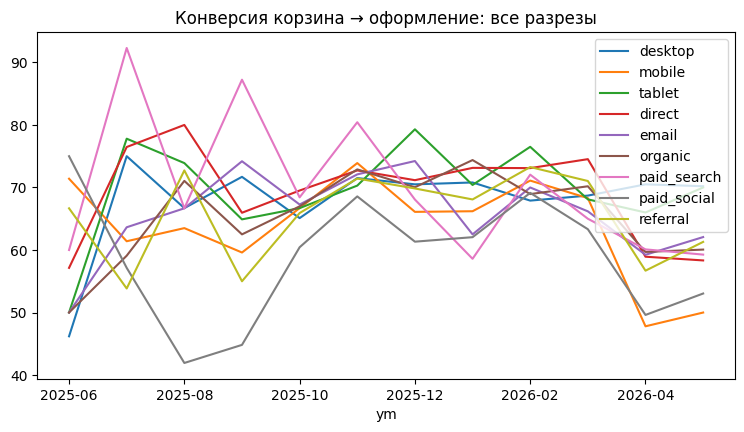

In [103]:
import matplotlib.pyplot as plt

g2 = df.groupby(["ym", "source"]).agg(cart=("cart", "sum"), chk=("chk", "sum"))
conv_src = (g2["chk"] / g2["cart"] * 100).unstack()

everything = pd.concat([conv, conv_src], axis=1)
everything.plot(figsize=(9, 4.5), title="Конверсия корзина → оформление: все разрезы")
plt.show()

### Одна мысль на холст

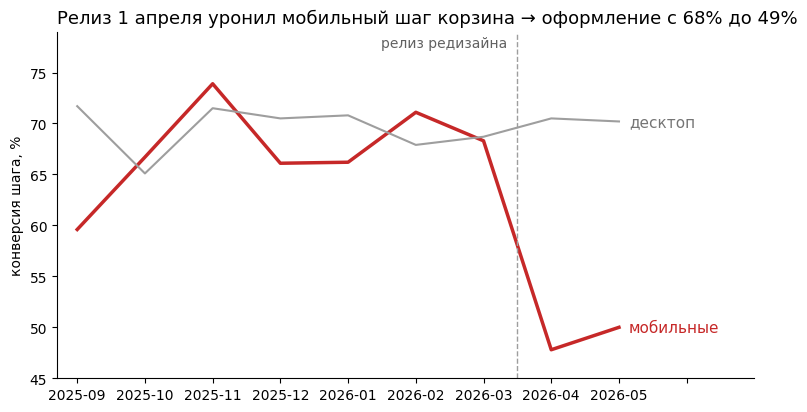

In [104]:
trimmed = conv.loc["2025-09":]

fig, ax = plt.subplots(figsize=(9, 4.5))
trimmed["mobile"].plot(ax=ax, color="#c62828", linewidth=2.5)
trimmed["desktop"].plot(ax=ax, color="#9e9e9e", linewidth=1.5)

ax.axvline(6.5, color="#9e9e9e", linestyle="--", linewidth=1)
ax.text(6.35, 77.5, "релиз редизайна", ha="right", color="#616161", fontsize=10)
ax.text(8.15, trimmed["mobile"].iloc[-1], "мобильные", color="#c62828", va="center", fontsize=11)
ax.text(8.15, trimmed["desktop"].iloc[-1], "десктоп", color="#757575", va="center", fontsize=11)

ax.set_title("Релиз 1 апреля уронил мобильный шаг корзина → оформление с 68% до 49%", loc="left", fontsize=13)
ax.set_ylabel("конверсия шага, %")
ax.set_xlabel("")
ax.set_xlim(-0.3, 10)
ax.set_ylim(45, 79)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Дело закрыто: карта расследования и дорога дальше

In [105]:
import pandas as pd

base = "https://python-academy.org/static/product-analytics/dataset"

ab = pd.read_csv(f"{base}/ab_test_checkout.csv")
ab["chk"] = ab["reached_step"].isin(["checkout", "purchase"])
restored = ab[ab["variant"] == "A"]["chk"].mean() * 100
print(f"мир после отката: конверсия шага {restored:.1f}% (до поломки было 68.1%)")

мир после отката: конверсия шага 69.5% (до поломки было 68.1%)


# Дело закрыто

Правление слушало доклад четыре минуты. Решение принято: старая форма вернулась ко всем мобильным пользователям в тот же вечер.

Чем закончилась история — мы знали точнее любого прогноза, потому что будущее уже лежало в данных: группа A эксперимента четыре недели жила в мире, где откат случился. Конверсия шага в этой группе — **69.5%**, выше доапрельского уровня 68.1%. Откат не просто вернул конверсию — он её восстановил.

## Карта расследования

| Вопрос | Инструмент | Чем закончилось |
|---|---|---|
| Что значит «просели»? | определения метрик, знаменатели | жалоба стала измеримым вопросом |
| Что в данных? | head, describe, пропуски, дубли | четыре таблицы, год жизни магазина |
| Здоров или болен? | DAU/WAU/MAU, конверсия, чек, ARPU | трещина: конверсия −12% |
| Старые уходят или новые хуже? | когорты, retention, LTV | болезнь у новых когорт |
| Где теряются? | воронка, сегменты | шаг корзина → оформление, мобильные |
| Всегда или началось? | разрез по времени, естественный контроль | апрель, совпадает с релизом |
| Сколько стоит и как доказать? | гипотеза, оценка на салфетке | ~11.6 млн ₽/мес, нужен эксперимент |
| Правда ли виноват редизайн? | A/A, p-value, дизайн, анализ A/B | +21 п.п., p < 0.001 |
| Как превратить в решение? | отчёт-пирамида, график-вывод | четыре минуты до решения |

## Итоговые цифры

- **68% → 49%** — падение конверсии шага корзина → оформление
- **+21 п.п., p < 0.001** — эффект отката, доказан экспериментом
- **69.5%** — конверсия в группе A («мир после отката»)
- **+4821 ₽ с корзины** — эффект старой формы
- **~14 млн ₽/мес** — недополученная выручка
- **3000 корзин, 4 недели** — размер эксперимента

## Стек и воспроизводимость

Python 3.10+, pandas, numpy, matplotlib. Все числа воспроизводятся прогоном ноутбука из сырых CSV. Ни одно число в выводах не берётся «на глаз» — каждое пересчитывается кодом.